# Where do the stars come from?

Games played measures whether a pick became a regular player. This notebook
looks at the **best** players instead, and how they entered the AFL.

1. **The top 36 players** by Brownlow votes over 2024–2026.
2. **Each club's top 2** by Brownlow votes earned for that club over 2024–2026.
3. **All-Australian teams** 2024–2026, a position-balanced cross-check, because
   Brownlow votes favour midfielders.
4. **The star-probability curve:** for each national draft pick (2005–2018), the
   chance of becoming a top-36 player. Its definitions were
   [written down first](../docs/star_curve_definitions.md).

Parts 1–3 are descriptive. Brownlow votes come from AFL Tables, and entry routes
and trades come from DraftGuru's year pages.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.afltables import all_season_games
from afl.analysis import bootstrap, games_before_draft
from afl.datasets import draft_outcomes
from afl.draft_charts import BLUE, BLUE_BAND, GREY, INK, ORANGE, TITLE, apply_style
from afl.match import TEAM_NAMES, load_manual_matches, match_picks
from afl.stars import (all_australian, all_movements, entry_routes, match_to_draftguru,
                       top_per_club, top_players)

N_BOOT = 2000
WINDOW = (2024, 2026)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)
apply_style()

seasons = all_season_games(1995, 2026)
moves = all_movements(2005, 2025)  # 2025 adds the latest trades (e.g. Petracca to Gold Coast)
print(f"{len(seasons)} player-seasons 1995-2026  |  {len(moves)} DraftGuru movements 2005-2025")


def first_entries(first_year, last_year):
    """Each player's first DraftGuru entry (not a trade or free agency) in these years,
    dropping anyone who had already played AFL games: those are veterans
    re-entering (e.g. via the pre-season draft), not new players."""
    rows = moves[~moves["draft"].isin(["Trade", "Free Agency"]) & moves["year"].between(first_year, last_year)]
    # Movements already carry draft_year (the same as year), so drop the duplicate
    rows = rows.sort_values("year").drop_duplicates("draftguru_url").drop(columns="year")
    found = match_picks(rows.reset_index(drop=True), seasons[seasons["season"] >= 2006], load_manual_matches())
    found["prior_games"] = games_before_draft(found, seasons)
    print(f"  {first_year}-{last_year}: {len(found)} first entries, "
          f"{(found['prior_games'] > 0).sum()} dropped as veterans with earlier AFL games")
    found = found[found["prior_games"] == 0]
    return found.rename(columns={"draft": "entry_route", "pick": "entry_pick"})

19712 player-seasons 1995-2026  |  3429 DraftGuru movements 2005-2025


In [2]:
BANDS = [("National 1–10", 1, 10), ("National 11–20", 11, 20),
         ("National 21–40", 21, 40), ("National 41+", 41, 999)]
ROUTE_ORDER = [b[0] for b in BANDS] + ["Rookie", "Mid-Season", "Other route"]


def route_band(row):
    """Group an entry route into the bands used in every table and chart."""
    if row["entry_route"] == "National":
        return next(label for label, lo, hi in BANDS if lo <= row["entry_pick"] <= hi)
    if row["entry_route"] in ("Rookie", "Mid-Season"):
        return row["entry_route"]
    return "Other route"


def describe(players, club_col="club"):
    """Add entry route, band, and whether the player's club drafted him."""
    routes = entry_routes(players["draftguru_url"], moves).drop_duplicates("draftguru_url")
    out = players.merge(routes, on="draftguru_url", how="left")
    out["route_band"] = out.apply(route_band, axis=1)
    out["drafted_by_club"] = out[club_col] == out["entry_club"]
    out["mature_age"] = out["age_at_entry"] >= 19.0
    return out


def summarise(df, label):
    """One row of shares for a group of players."""
    shares = df["route_band"].value_counts(normalize=True).reindex(ROUTE_ORDER, fill_value=0)
    row = {"group": label, "players": len(df), **shares.to_dict()}
    row["Academy / father-son"] = df["bid_matched"].mean()
    row["Not drafted by current club"] = 1 - df["drafted_by_club"].mean()
    row["Mature-age at entry"] = df["mature_age"].mean()
    return row

## Base rate: how do all players enter the AFL?

To judge whether stars come from somewhere unusual, we need to know how
*everyone* gets in. This counts every first entry (not trades or free agency)
in DraftGuru's 2008–2023 year pages, which covers the years today's stars were
drafted. Veterans re-entering after earlier AFL careers are left out.

In [3]:
base = first_entries(2008, 2023)
base["route_band"] = base.apply(route_band, axis=1)
base_shares = base["route_band"].value_counts(normalize=True).reindex(ROUTE_ORDER, fill_value=0)
print(f"First entries, 2008-2023: {len(base)}")
(base_shares * 100).round(1).rename("% of all entrants").to_frame()

  2008-2023: 2017 first entries, 82 dropped as veterans with earlier AFL games
First entries, 2008-2023: 1935


,% of all entrants
route_band,
National 1–10,8.3
National 11–20,8.3
National 21–40,16.4
National 41+,23.9
Rookie,26.9
Mid-Season,3.8
Other route,12.5


## 1. The top 36 players, 2024–2026

Ranked by total Brownlow votes over the three seasons. Two players tie for
36th, so there are 37.

In [4]:
core = describe(match_to_draftguru(top_players(seasons, *WINDOW), moves, seasons))
print(core["match_status"].value_counts().to_string())
core[["rank", "player", "club", "votes", "games", "route_band", "entry_year", "entry_pick",
      "entry_club", "moved_to", "signing", "age_at_entry"]].round(1)

match_status
name    37


,rank,player,club,votes,games,route_band,entry_year,entry_pick,entry_club,moved_to,signing,age_at_entry
0,1,Nick Daicos,Collingwood,117,71,National 1–10,2021,4.0,Collingwood,,Father-Son (Peter Daicos),18.9
1,2,Patrick Cripps,Carlton,91,72,National 11–20,2013,13.0,Carlton,,,18.7
2,3,Marcus Bontempelli,Western Bulldogs,78,66,National 1–10,2013,4.0,Western Bulldogs,,,18.0
3,4,Zak Butters,Port Adelaide,76,63,National 11–20,2018,12.0,Port Adelaide,,,18.2
4,4,Matt Rowell,Gold Coast,76,66,National 1–10,2019,1.0,Gold Coast,,,18.4
5,6,Isaac Heeney,Sydney,71,67,National 11–20,2014,18.0,Sydney,,Academy (Sydney),18.6
6,7,Caleb Serong,Fremantle,67,71,National 1–10,2019,8.0,Fremantle,,,18.8
7,8,Jordan Dawson,Adelaide,66,69,National 41+,2015,56.0,Sydney,Adelaide,,18.6
8,9,Bailey Smith,Geelong,65,47,National 1–10,2018,7.0,Western Bulldogs,Geelong,,18.0
9,10,Max Gawn,Melbourne,64,68,National 21–40,2009,34.0,Melbourne,,,17.9


## 2. Each club's top 2, 2024–2026

Ranked by Brownlow votes earned **for that club**. Ties at 2nd place are
included.

In [5]:
per_club = describe(match_to_draftguru(top_per_club(seasons, *WINDOW), moves, seasons))
print(per_club["match_status"].value_counts().to_string())
per_club[["club", "rank", "player", "votes", "route_band", "entry_year", "entry_pick",
          "entry_club", "drafted_by_club", "signing"]].round(1)

match_status
name    38


,club,rank,player,votes,route_band,entry_year,entry_pick,entry_club,drafted_by_club,signing
0,Adelaide,1,Jordan Dawson,66,National 41+,2015,56.0,Sydney,False,
1,Adelaide,2,Izak Rankine,45,National 1–10,2018,3.0,Gold Coast,False,
2,Brisbane,1,Lachie Neale,58,National 41+,2011,58.0,Fremantle,False,
3,Brisbane,2,Will Ashcroft,38,National 1–10,2022,2.0,Brisbane,True,Father-Son (Marcus Ashcroft)
4,Carlton,1,Patrick Cripps,91,National 11–20,2013,13.0,Carlton,True,
5,Carlton,2,Sam Walsh,36,National 1–10,2018,1.0,Carlton,True,
6,Collingwood,1,Nick Daicos,117,National 1–10,2021,4.0,Collingwood,True,Father-Son (Peter Daicos)
7,Collingwood,2,Jordan de Goey,17,National 1–10,2014,5.0,Collingwood,True,
8,Collingwood,2,Josh Daicos,17,National 41+,2016,57.0,Collingwood,True,Father-Son (Peter Daicos)
9,Essendon,1,Zach Merrett,41,National 21–40,2013,26.0,Essendon,True,


In [6]:
home = per_club.groupby("club")["drafted_by_club"].agg(["sum", "size"])
home.columns = ["drafted by club", "players"]
print(f"Club top-2 players drafted by their own club: {home['drafted by club'].sum()} of {home['players'].sum()}")
home.sort_values("drafted by club").T

Club top-2 players drafted by their own club: 29 of 38


club,Adelaide,Geelong,Brisbane,Richmond,Port Adelaide,Hawthorn,Sydney,St Kilda,North Melbourne,Melbourne,Gold Coast,GWS,Fremantle,Essendon,Carlton,West Coast,Western Bulldogs,Collingwood
drafted by club,0,0,1,1,1,1,2,2,2,2,2,2,2,2,2,2,2,3
players,2,2,2,3,2,2,2,2,2,2,2,2,2,2,2,2,2,3


## 3. All-Australian teams, 2024–2026

DraftGuru's All-Australian pages link straight to each player's DraftGuru page,
so no name matching is needed. The 2026 team has 23 players (5 on the
interchange); 2024 and 2025 have 22.

Dayne Zorko's first DraftGuru record is a trade, because his 2011 pre-listing
with Brisbane is recorded that way. DraftGuru's own summary says "Prelist 2011",
so he's counted under "Other route".

In [7]:
aa = pd.concat([all_australian(year) for year in range(WINDOW[0], WINDOW[1] + 1)])
print(aa.groupby("year").size().to_string())
selections = aa.groupby("draftguru_url").agg(
    player=("player", "last"), club=("club", "last"), selections=("year", "size"),
    positions=("position", lambda p: ", ".join(p)), drafted=("drafted", "first"))
aa_players = describe(selections.reset_index())
print(f"\n{len(aa)} selections, {len(aa_players)} different players")
aa_players.sort_values("selections", ascending=False)[
    ["player", "club", "selections", "positions", "route_band", "drafted", "entry_club"]]

year
2024    22
2025    22
2026    23

67 selections, 50 different players


,player,club,selections,positions,route_band,drafted,entry_club
33,Marcus Bontempelli,Western Bulldogs,3,"C, IC, C",National 1–10,#4 National 2013,Western Bulldogs
35,Max Gawn,Melbourne,3,"Ru, Ru, Ru",National 21–40,#34 National 2009,Melbourne
39,Nick Daicos,Collingwood,3,"W, IC, Ro",National 1–10,#4 National 2021,Collingwood
49,Zak Butters,Port Adelaide,2,"IC, IC",National 11–20,#12 National 2018,Port Adelaide
12,Harris Andrews,Brisbane,2,"CHB, CHB",National 41+,#61 National 2014,Brisbane
26,Kysaiah Pickett,Melbourne,2,"FP, HFF",National 11–20,#12 National 2019,Melbourne
23,Jordan Dawson,Adelaide,2,"C, RR",National 41+,#56 National 2015,Sydney
22,Jordan Clark,Fremantle,2,"BP, HBF",National 11–20,#15 National 2018,Geelong
19,Jeremy Cameron,Geelong,2,"CHF, CHF",Other route,GWS Underage 2010,GWS
37,Nasiah Wanganeen-Milera,St Kilda,2,"HBF, IC",National 11–20,#11 National 2021,St Kilda


## Comparing the three lists with the base rate

Shares of each group by how the player entered the AFL. The last three rows
are flags, so they don't add up to 100%.

In [8]:
rows = [summarise(core, "Top 36 (Brownlow)"),
        summarise(per_club, "Top 2 per club (Brownlow)"),
        summarise(aa_players, "All-Australians")]
base_row = {"group": "All entrants 2008–2023", "players": len(base), **base_shares.to_dict()}
compare = pd.DataFrame(rows + [base_row]).set_index("group").T
compare.loc[compare.index != "players"] = (compare.loc[compare.index != "players"].astype(float) * 100).round(0)
compare

group,Top 36 (Brownlow),Top 2 per club (Brownlow),All-Australians,All entrants 2008–2023
players,37.0,38.0,50.0,1935.0
National 1–10,57.0,50.0,28.0,8.0
National 11–20,22.0,16.0,22.0,8.0
National 21–40,11.0,13.0,18.0,16.0
National 41+,5.0,11.0,14.0,24.0
Rookie,0.0,3.0,10.0,27.0
Mid-Season,3.0,3.0,0.0,4.0
Other route,3.0,5.0,8.0,13.0
Academy / father-son,14.0,18.0,12.0,NaN
Not drafted by current club,27.0,24.0,26.0,NaN


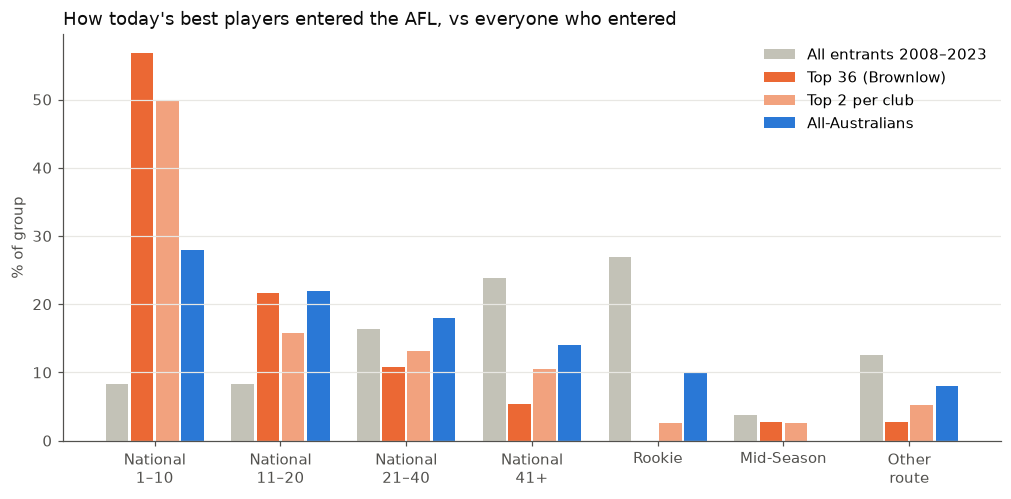

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.8))
groups = [("All entrants 2008–2023", base_shares, GREY),
          ("Top 36 (Brownlow)", pd.Series(rows[0]).reindex(ROUTE_ORDER).astype(float), ORANGE),
          ("Top 2 per club", pd.Series(rows[1]).reindex(ROUTE_ORDER).astype(float), "#f2a27e"),
          ("All-Australians", pd.Series(rows[2]).reindex(ROUTE_ORDER).astype(float), BLUE)]
x = np.arange(len(ROUTE_ORDER))
width = 0.2
for i, (label, shares, colour) in enumerate(groups):
    ax.bar(x + (i - 1.5) * width, shares.values * 100, width=width * 0.9, color=colour, label=label)
ax.set_xticks(x, [r.replace(" ", "\n", 1) for r in ROUTE_ORDER])
ax.set_ylabel("% of group")
ax.grid(axis="x", visible=False)
ax.set_title("How today's best players entered the AFL, vs everyone who entered",
             loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper right")
plt.show()

## 4. The star-probability curve (2005–2018 drafts)

Definitions are as [written down before computing](../docs/star_curve_definitions.md):

- **Star season:** a top-36 finish for Brownlow votes in a season.
- **Main outcome:** at least one star season in the first 8 seasons after the draft.
- **Second outcome:** two or more star seasons in that window.
- **Curve:** the share of picks within ±5 of each pick number.

In [10]:
votes = seasons[seasons["season"].between(2006, 2026)].groupby(["season", "afltables_url"])[
    "brownlow_votes"].sum().reset_index()
votes["rank"] = votes.groupby("season")["brownlow_votes"].rank(ascending=False, method="min")
star_seasons = votes[votes["rank"] <= 36]
print("Star seasons per year:", star_seasons.groupby("season").size().agg(["min", "max"]).to_dict())

picks = draft_outcomes(2005, 2018, windows=(8,))
joined = picks[["afltables_url", "draft_year"]].reset_index().merge(star_seasons, on="afltables_url")
in_window = joined[(joined["season"] > joined["draft_year"]) & (joined["season"] <= joined["draft_year"] + 8)]
picks["star_seasons"] = in_window.groupby("index").size().reindex(picks.index, fill_value=0)
picks["star"] = (picks["star_seasons"] >= 1).astype(float)
picks["star_2plus"] = (picks["star_seasons"] >= 2).astype(float)
picks["not_bust"] = (picks["games_8"] >= 50).astype(float)
print(f"Picks 1-80: {len(picks)}  |  1+ star season: {int(picks['star'].sum())}  |  2+: {int(picks['star_2plus'].sum())}")

Star seasons per year: {'min': 36, 'max': 42}


Picks 1-80: 1004  |  1+ star season: 101  |  2+: 60


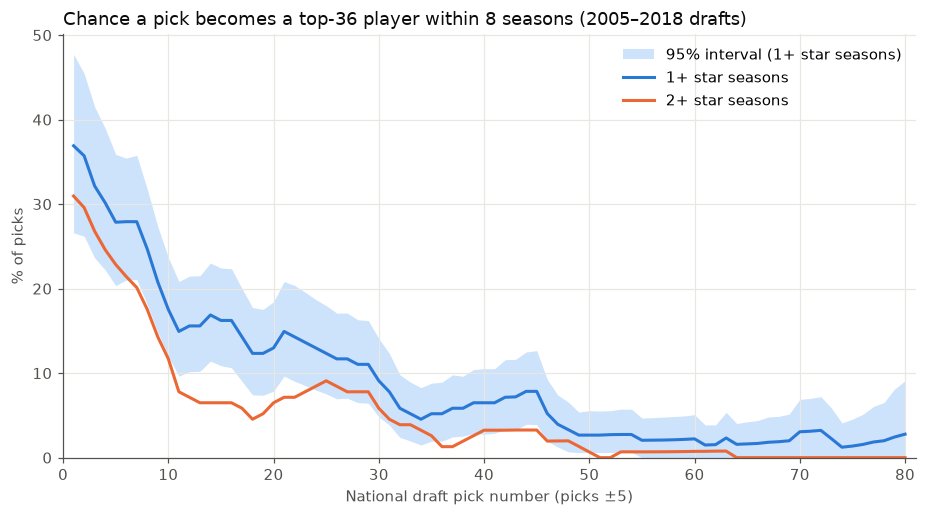

In [11]:
STAR_WINDOW = 5
PICKS = np.arange(1, 81)


def curve(pick, outcome):
    """Share of picks within +/- STAR_WINDOW of each pick number with outcome == 1."""
    n = np.bincount(pick, minlength=81)[1:]
    hits = np.bincount(pick, weights=outcome, minlength=81)[1:]
    kernel = np.ones(2 * STAR_WINDOW + 1)
    return np.convolve(hits, kernel, "same") / np.convolve(n, kernel, "same")


def curve_with_band(col):
    pick, outcome = picks["pick"].to_numpy(), picks[col].to_numpy()
    rng = np.random.default_rng(2026)
    boots = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(pick), len(pick))
        boots.append(curve(pick[i], outcome[i]))
    low, high = np.percentile(boots, [2.5, 97.5], axis=0)
    return curve(pick, outcome), low, high


star_curve = curve_with_band("star")
star2_curve = curve_with_band("star_2plus")

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(PICKS, star_curve[1] * 100, star_curve[2] * 100, color=BLUE_BAND, linewidth=0,
                label="95% interval (1+ star seasons)")
ax.plot(PICKS, star_curve[0] * 100, color=BLUE, linewidth=2, label="1+ star seasons")
ax.plot(PICKS, star2_curve[0] * 100, color=ORANGE, linewidth=2, label="2+ star seasons")
ax.set_xlim(0, 81)
ax.set_ylim(bottom=0)
ax.set_xlabel("National draft pick number (picks ±5)")
ax.set_ylabel("% of picks")
ax.set_title("Chance a pick becomes a top-36 player within 8 seasons (2005–2018 drafts)",
             loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [12]:
STAR_BANDS = [(1, 5), (6, 10), (11, 20), (21, 30), (31, 40), (41, 60), (61, 80)]
rows = []
for lo, hi in STAR_BANDS:
    g = picks[picks["pick"].between(lo, hi)]
    row = {"picks": f"{lo}–{hi}", "n": len(g)}
    for col, label in [("not_bust", "50+ games"), ("star", "1+ star seasons"),
                       ("star_2plus", "2+ star seasons")]:
        est, low, high = bootstrap(g, lambda d: d[col].mean() * 100, n=N_BOOT)
        row[label] = round(est, 1)
        row[f"{label} CI"] = f"{low:.0f}–{high:.0f}"
    rows.append(row)
bands = pd.DataFrame(rows).set_index("picks")
bands

,n,50+ games,50+ games CI,1+ star seasons,1+ star seasons CI,2+ star seasons,2+ star seasons CI
picks,,,,,,,
1–5,70,92.9,87–99,42.9,31–54,35.7,24–47
6–10,70,84.3,76–91,12.9,6–21,10.0,4–17
11–20,140,67.1,59–75,17.1,11–24,6.4,3–11
21–30,140,65.7,58–74,12.9,7–19,9.3,5–14
31–40,140,46.4,38–55,4.3,1–8,1.4,0–4
41–60,271,37.6,32–44,4.1,2–7,1.5,0–3
61–80,173,24.3,18–31,1.7,0–4,0.0,0–0


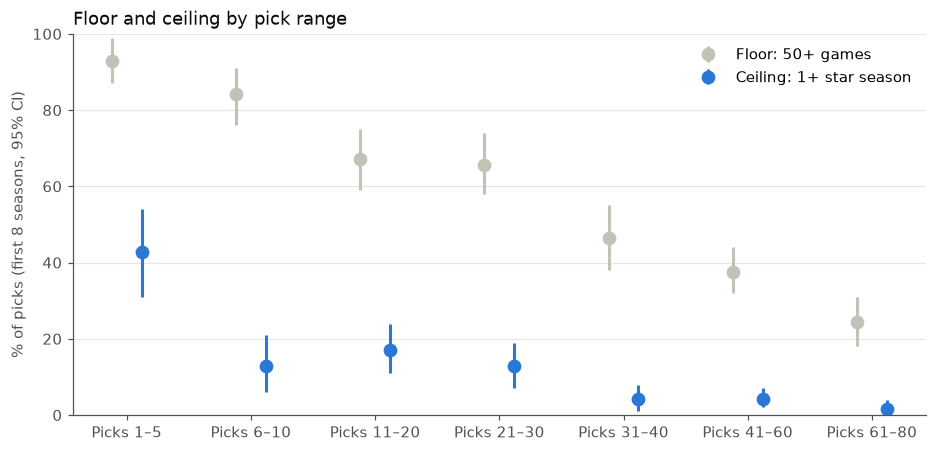

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(bands))
for col, colour, offset in [("50+ games", GREY, -0.12), ("1+ star seasons", BLUE, 0.12)]:
    lows = bands[f"{col} CI"].str.split("–").str[0].astype(float)
    highs = bands[f"{col} CI"].str.split("–").str[1].astype(float)
    ax.errorbar(x + offset, bands[col], yerr=[bands[col] - lows, highs - bands[col]], fmt="o",
                color=colour, markersize=8, capsize=0, elinewidth=2,
                label="Floor: 50+ games" if col == "50+ games" else "Ceiling: 1+ star season")
ax.set_xticks(x, [f"Picks {p}" for p in bands.index])
ax.set_ylim(0, 100)
ax.set_ylabel("% of picks (first 8 seasons, 95% CI)")
ax.grid(axis="x", visible=False)
ax.set_title("Floor and ceiling by pick range", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper right")
plt.show()

### Mature-age vs junior star rates (exploratory)

The actual star rate minus the expected star rate at the same picks (the ±5
curve). This revisits notebook 04's ceiling result using star seasons rather
than 150+ games.

In [14]:
picks["expected_star"] = curve(picks["pick"].to_numpy(), picks["star"].to_numpy())[picks["pick"] - 1]
picks["resid_star"] = picks["star"] - picks["expected_star"]
aged = picks[picks["age"].notna()]
rows = []
for label, g in [("Mature-age (19.0+)", aged[aged["mature_age"]]), ("Junior", aged[~aged["mature_age"]])]:
    est, low, high = bootstrap(g, lambda d: d["resid_star"].mean() * 100, n=N_BOOT)
    rows.append({"group": label, "n": len(g), "actual star rate": f"{g['star'].mean():.1%}",
                 "expected at their picks": f"{g['expected_star'].mean():.1%}",
                 "difference (pts)": round(est, 1), "CI": f"{low:+.1f} to {high:+.1f}"})
pd.DataFrame(rows).set_index("group")

,n,actual star rate,expected at their picks,difference (pts),CI
group,,,,,
Mature-age (19.0+),155,4.5%,4.6%,-0.1,-2.8 to +3.4
Junior,848,11.1%,10.9%,0.2,-1.8 to +2.2


### Where star seasons come from

Every star season in 2006–2026 by a player who **entered the AFL between 2005
and 2018**, by entry route. This includes rookie and other entries, which the
curve above leaves out.

- Players who entered before 2005 (e.g. Ablett, Judd, Franklin) are left out,
  including those who changed clubs later.
- So is anyone who had already played AFL games before the entry recorded here.

In [15]:
star_players = (star_seasons.merge(seasons[["afltables_url", "player"]].drop_duplicates("afltables_url"),
                                   on="afltables_url"))
matched = match_to_draftguru(star_players.drop_duplicates("afltables_url"), moves, seasons)
print("Matching star-season players to DraftGuru:", matched["match_status"].value_counts().to_dict())

debut = seasons.groupby("afltables_url")["season"].min()
unmatched = matched[matched["draftguru_url"].isna()]
print(f"Unmatched players who debuted in 2005 or earlier (entered before DraftGuru's years): "
      f"{(unmatched['afltables_url'].map(debut) <= 2005).sum()} of {len(unmatched)}")

routes = entry_routes(matched["draftguru_url"].dropna(), moves).drop_duplicates("draftguru_url")
routes = routes.merge(matched[["draftguru_url", "afltables_url"]], on="draftguru_url")
routes["prior_games"] = games_before_draft(routes.rename(columns={"entry_year": "draft_year"}), seasons)
routes = routes[routes["entry_year"].between(2005, 2018) & (routes["prior_games"] == 0)]
routes["route_band"] = routes.apply(route_band, axis=1)
by_route = (star_seasons.merge(matched[["afltables_url", "draftguru_url"]], on="afltables_url")
            .merge(routes[["draftguru_url", "route_band"]], on="draftguru_url"))
print(f"Star seasons by 2005-2018 entrants: {len(by_route)} (from {by_route['draftguru_url'].nunique()} players)")

entrants_0518 = first_entries(2005, 2018)
entrants_0518["route_band"] = entrants_0518.apply(route_band, axis=1)

pd.DataFrame({
    "% of star seasons": by_route["route_band"].value_counts(normalize=True).reindex(ROUTE_ORDER, fill_value=0) * 100,
    "% of entrants 2005–2018": entrants_0518["route_band"].value_counts(normalize=True).reindex(ROUTE_ORDER, fill_value=0) * 100,
}).round(1)

Matching star-season players to DraftGuru: {'name': 203, 'unmatched': 65, 'name + club': 3, 'manual': 1}
Unmatched players who debuted in 2005 or earlier (entered before DraftGuru's years): 65 of 65


Star seasons by 2005-2018 entrants: 480 (from 142 players)


  2005-2018: 1835 first entries, 74 dropped as veterans with earlier AFL games


,% of star seasons,% of entrants 2005–2018
route_band,,
National 1–10,39.2,8.0
National 11–20,15.8,8.0
National 21–40,20.6,15.8
National 41+,11.7,24.5
Rookie,6.0,33.5
Mid-Season,0.0,0.5
Other route,6.7,9.8


## 5. Picks 1–5, one at a time (descriptive)

How does each of the first five picks do on its own? Each pick has only **14
players** (one per draft, 2005–2018), so the intervals are wide.

- **Within 8 seasons:** games, and star seasons (top 36 for Brownlow votes),
  as in Part 4.
- **Career to 2026:** shown for context. These favour earlier drafts.

In [16]:
career_stars = star_seasons.groupby("afltables_url").size()
top5 = picks[picks["pick"] <= 5].copy()
top5["career_star_seasons"] = top5["afltables_url"].map(career_stars).fillna(0).astype(int)

rows = []
for pick, g in top5.groupby("pick"):
    star_rate = bootstrap(g, lambda d: d["star"].mean() * 100, n=N_BOOT)
    rows.append({
        "pick": pick, "n": len(g),
        "median games (8 seasons)": g["games_8"].median(),
        "50+ games": f"{(g['games_8'] >= 50).sum()} of {len(g)}",
        "1+ star season (8 seasons)": f"{int(g['star'].sum())} of {len(g)}",
        "star rate CI": f"{star_rate[1]:.0f}–{star_rate[2]:.0f}%",
        "2+ star seasons (8 seasons)": f"{int(g['star_2plus'].sum())} of {len(g)}",
        "1+ star season (career)": f"{(g['career_star_seasons'] >= 1).sum()} of {len(g)}",
    })
pd.DataFrame(rows).set_index("pick")

,n,median games (8 seasons),50+ games,1+ star season (8 seasons),star rate CI,2+ star seasons (8 seasons),1+ star season (career)
pick,,,,,,,
1,14,150.5,14 of 14,4 of 14,7–50%,4 of 14,4 of 14
2,14,139.5,12 of 14,8 of 14,29–79%,6 of 14,8 of 14
3,14,133.5,14 of 14,7 of 14,21–79%,5 of 14,7 of 14
4,14,119.5,11 of 14,5 of 14,14–64%,4 of 14,6 of 14
5,14,137.5,14 of 14,6 of 14,14–71%,6 of 14,6 of 14


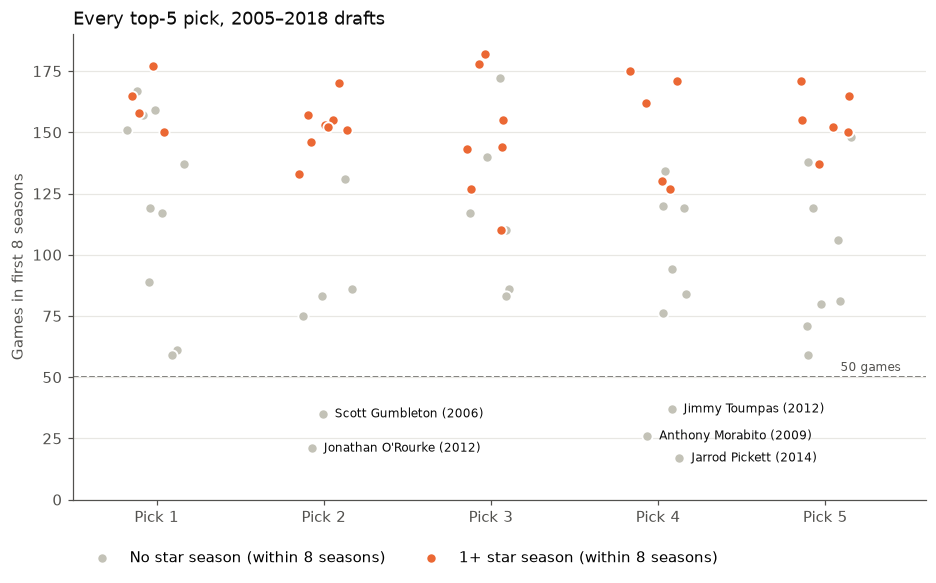

In [17]:
fig, ax = plt.subplots(figsize=(10, 5.5))
# Spread points sideways a little so they don't overlap; labels use the same positions
top5["x"] = top5["pick"] + np.random.default_rng(3).uniform(-0.18, 0.18, len(top5))
for star, colour, label in [(0, GREY, "No star season"), (1, ORANGE, "1+ star season")]:
    g = top5[top5["star"] == star]
    ax.scatter(g["x"], g["games_8"], s=45, color=colour,
               edgecolors="white", linewidths=1.2, zorder=3, label=f"{label} (within 8 seasons)")
for row in top5[top5["games_8"] < 50].itertuples():
    ax.annotate(f"{row.player} ({row.draft_year})", (row.x, row.games_8), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8, color=TITLE)
ax.axhline(50, color=INK, linewidth=1, linestyle="--", zorder=0)
ax.annotate("50 games", (5.45, 50), xytext=(0, 4), textcoords="offset points", fontsize=8,
            color=INK, ha="right")
ax.set_xticks(range(1, 6), [f"Pick {p}" for p in range(1, 6)])
ax.set_xlim(0.5, 5.6)
ax.set_ylim(bottom=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Games in first 8 seasons")
ax.set_title("Every top-5 pick, 2005–2018 drafts", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2)
plt.show()

In [18]:
top5.sort_values(["pick", "draft_year"])[
    ["pick", "draft_year", "player", "club", "pick_note", "signing", "games_8", "star_seasons",
     "games_after_draft", "career_star_seasons"]
].rename(columns={"games_8": "games (8 seasons)", "star_seasons": "star seasons (8 seasons)",
                  "games_after_draft": "games (career)", "career_star_seasons": "star seasons (career)"})

,pick,draft_year,player,club,pick_note,signing,games (8 seasons),star seasons (8 seasons),games (career),star seasons (career)
0,1,2005,Marc Murphy,Carlton,Priority (Carlton),,165.0,5,300,6
66,1,2006,Bryce Gibbs,Carlton,,,177.0,2,268,4
145,1,2007,Matthew Kreuzer,Carlton,Priority (Carlton),,119.0,0,189,0
212,1,2008,Jack Watts,Melbourne,,,137.0,0,174,0
291,1,2009,Tom Scully,Melbourne,Priority (Melbourne),,151.0,0,187,0
365,1,2010,David Swallow,Gold Coast,,,117.0,0,249,0
444,1,2011,Jonathon Patton,GWS,,,89.0,0,95,0
518,1,2012,Lachie Whitfield,GWS,,,150.0,2,278,2
587,1,2013,Tom Boyd,GWS,,,61.0,0,61,0
649,1,2014,Paddy McCartin,St Kilda,,,59.0,0,63,0


### Why does pick 1 have the lowest star rate?

Two things worth checking: **height** (Brownlow votes rarely go to key-position
players and rucks) and **the club** (2010–2013 top picks often went to the new
Gold Coast and GWS teams, which lost a lot early on, and losing teams poll fewer votes).

In [19]:
top5["tall"] = top5["height_cm"] >= 193
print("By pick: average height, number 193cm+, and star seasons within 8 seasons")
print(top5.groupby("pick").agg(average_height=("height_cm", "mean"), tall_193_plus=("tall", "sum"),
                               with_star_season=("star", "sum")).round(1).to_string())

print("\nAll top-5 picks, by height")
print(top5.groupby("tall").agg(picks=("pick", "size"), with_star_season=("star", "sum"),
                               played_50_plus=("games_8", lambda g: (g >= 50).sum()))
      .rename(index={False: "under 193cm", True: "193cm+"}).to_string())

top5["expansion_club"] = top5["club"].isin(["Gold Coast", "GWS"])
print("\nAll top-5 picks, by drafting club")
print(top5.groupby("expansion_club").agg(picks=("pick", "size"), with_star_season=("star", "sum"),
                                         played_50_plus=("games_8", lambda g: (g >= 50).sum()),
                                         median_games=("games_8", "median"))
      .rename(index={False: "Other clubs", True: "Gold Coast / GWS"}).to_string())

By pick: average height, number 193cm+, and star seasons within 8 seasons
      average_height  tall_193_plus  with_star_season
pick                                                 
1              189.6              6               4.0
2              188.4              4               8.0
3              186.7              2               7.0
4              188.7              4               5.0
5              188.1              1               6.0

All top-5 picks, by height
             picks  with_star_season  played_50_plus
tall                                                
under 193cm     53              28.0              49
193cm+          17               2.0              16

All top-5 picks, by drafting club
                  picks  with_star_season  played_50_plus  median_games
expansion_club                                                         
Other clubs          50              24.0              47         145.0
Gold Coast / GWS     20               6.0              18

## 6. A broader star: Brownlow top 36 **or** All-Australian

The Brownlow rarely rewards key defenders, rucks and key forwards. So, as set
out in the [definitions addendum](../docs/star_curve_definitions.md) (written
before this was computed), a **broad star season** is a season in the top 36
for Brownlow votes **or** in that season's All-Australian team. Everything else
is unchanged: national picks 1–80 from 2005–2018, within the first 8 seasons.

In [20]:
aa_all = pd.concat([all_australian(year) for year in range(2006, 2027)])
print("All-Australian team sizes:", aa_all.groupby("year").size().agg(["min", "max"]).to_dict())

# Seasons in each pick's window when he was All-Australian (joined on DraftGuru URL)
aa_hits = (picks[["draftguru_url", "draft_year"]].reset_index()
           .merge(aa_all[["draftguru_url", "year"]], on="draftguru_url"))
aa_hits = aa_hits[(aa_hits["year"] > aa_hits["draft_year"]) & (aa_hits["year"] <= aa_hits["draft_year"] + 8)]
aa_hits = aa_hits.rename(columns={"year": "season"})[["index", "season"]]

# Broad star seasons: the union of Brownlow top-36 seasons and All-Australian seasons
brownlow_hits = in_window[["index", "season"]]
broad_hits = pd.concat([brownlow_hits, aa_hits]).drop_duplicates()

picks["aa_seasons"] = aa_hits.groupby("index").size().reindex(picks.index, fill_value=0)
picks["broad_seasons"] = broad_hits.groupby("index").size().reindex(picks.index, fill_value=0)
picks["aa_star"] = (picks["aa_seasons"] >= 1).astype(float)
picks["broad_star"] = (picks["broad_seasons"] >= 1).astype(float)
picks["broad_star_2plus"] = (picks["broad_seasons"] >= 2).astype(float)

redrafted = picks[picks["draftguru_url"].duplicated(keep=False) & (picks["aa_seasons"] > 0)]
print(f"Re-drafted players with an All-Australian season in a window: {redrafted['draftguru_url'].nunique()}")
print(f"Picks with 1+ star season  Brownlow: {int(picks['star'].sum())}  |  All-Australian: "
      f"{int(picks['aa_star'].sum())}  |  broad: {int(picks['broad_star'].sum())}")
print(f"All-Australian but never Brownlow top 36 in the window: "
      f"{int(((picks['aa_star'] == 1) & (picks['star'] == 0)).sum())}")

All-Australian team sizes: {'min': 22, 'max': 23}
Re-drafted players with an All-Australian season in a window: 0
Picks with 1+ star season  Brownlow: 101  |  All-Australian: 89  |  broad: 139
All-Australian but never Brownlow top 36 in the window: 38


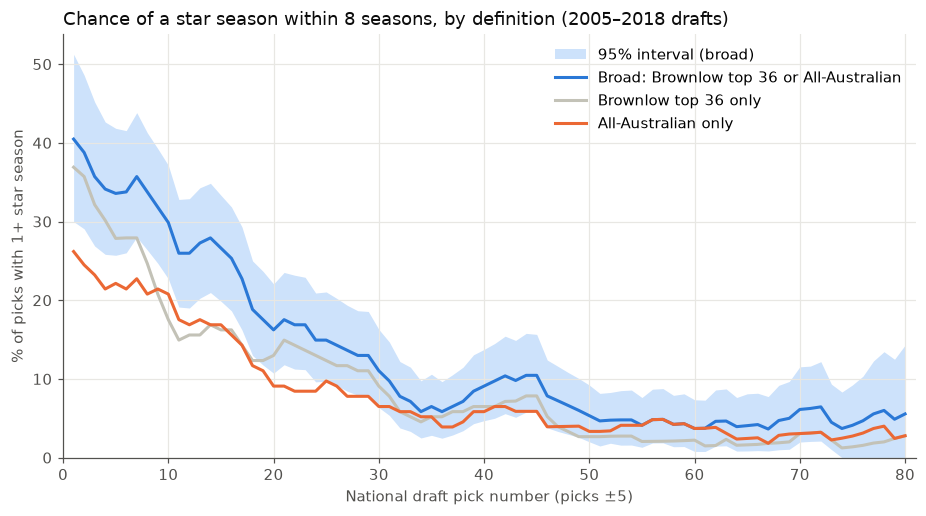

In [21]:
broad_curve = curve_with_band("broad_star")
aa_curve = curve(picks["pick"].to_numpy(), picks["aa_star"].to_numpy())

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(PICKS, broad_curve[1] * 100, broad_curve[2] * 100, color=BLUE_BAND, linewidth=0,
                label="95% interval (broad)")
ax.plot(PICKS, broad_curve[0] * 100, color=BLUE, linewidth=2, label="Broad: Brownlow top 36 or All-Australian")
ax.plot(PICKS, star_curve[0] * 100, color=GREY, linewidth=2, label="Brownlow top 36 only")
ax.plot(PICKS, aa_curve * 100, color=ORANGE, linewidth=2, label="All-Australian only")
ax.set_xlim(0, 81)
ax.set_ylim(bottom=0)
ax.set_xlabel("National draft pick number (picks ±5)")
ax.set_ylabel("% of picks with 1+ star season")
ax.set_title("Chance of a star season within 8 seasons, by definition (2005–2018 drafts)",
             loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [22]:
rows = []
for lo, hi in STAR_BANDS:
    g = picks[picks["pick"].between(lo, hi)]
    est, low, high = bootstrap(g, lambda d: d["broad_star"].mean() * 100, n=N_BOOT)
    rows.append({"picks": f"{lo}–{hi}", "n": len(g),
                 "Brownlow top 36": round(g["star"].mean() * 100, 1),
                 "All-Australian": round(g["aa_star"].mean() * 100, 1),
                 "Broad (either)": round(est, 1), "broad CI": f"{low:.0f}–{high:.0f}",
                 "Broad, 2+ seasons": round(g["broad_star_2plus"].mean() * 100, 1)})
print("% of picks with 1+ star season within 8 seasons")
pd.DataFrame(rows).set_index("picks")

% of picks with 1+ star season within 8 seasons


,n,Brownlow top 36,All-Australian,Broad (either),broad CI,"Broad, 2+ seasons"
picks,,,,,,
1–5,70,42.9,28.6,45.7,34–59,35.7
6–10,70,12.9,15.7,21.4,11–31,11.4
11–20,140,17.1,15.7,26.4,19–34,10.0
21–30,140,12.9,10.0,15.7,10–22,10.0
31–40,140,4.3,3.6,5.0,2–9,2.1
41–60,271,4.1,4.4,6.6,4–10,1.5
61–80,173,1.7,2.9,4.6,2–8,1.2


### Picks 1–5 with the broad definition

Does adding All-Australian selection lift pick 1, as the height explanation
in section 5 would predict?

In [23]:
top5_broad = picks[picks["pick"] <= 5].copy()
top5_broad["tall"] = top5_broad["height_cm"] >= 193
by_pick = top5_broad.groupby("pick").agg(
    n=("pick", "size"),
    brownlow_star=("star", "sum"),
    all_australian=("aa_star", "sum"),
    broad_star=("broad_star", "sum"),
).astype(int)
print(by_pick.to_string())

print("\nTop-5 picks by height (1+ star season within 8 seasons)")
print(top5_broad.groupby("tall").agg(picks=("pick", "size"), brownlow_star=("star", "sum"),
                                     all_australian=("aa_star", "sum"), broad_star=("broad_star", "sum"))
      .astype(int).rename(index={False: "under 193cm", True: "193cm+"}).to_string())

aa_only = top5_broad[(top5_broad["aa_star"] == 1) & (top5_broad["star"] == 0)]
print("\nTop-5 picks who were All-Australian but never Brownlow top 36 (within 8 seasons):")
print(aa_only[["pick", "draft_year", "player", "height_cm", "aa_seasons"]].to_string(index=False))

       n  brownlow_star  all_australian  broad_star
pick                                               
1     14              4               3           4
2     14              8               6           8
3     14              7               2           7
4     14              5               3           5
5     14              6               6           8

Top-5 picks by height (1+ star season within 8 seasons)
             picks  brownlow_star  all_australian  broad_star
tall                                                         
under 193cm     53             28              17          29
193cm+          17              2               3           3

Top-5 picks who were All-Australian but never Brownlow top 36 (within 8 seasons):
 pick  draft_year         player  height_cm  aa_seasons
    5        2008 Michael Hurley      195.0           1
    5        2012  Jake Stringer      191.0           1


### Do tall players just peak later? (exploratory, not in the definitions)

The 8-season window could cut off tall players who peak late. This counts
All-Australian selections over whole careers to 2026 for the top-5 picks, and
when each player was first selected.

In [24]:
career = (picks[picks["pick"] <= 5][["draftguru_url", "draft_year"]].reset_index()
          .merge(aa_all[["draftguru_url", "year"]], on="draftguru_url"))
career = career[career["year"] > career["draft_year"]]
career["season_no"] = career["year"] - career["draft_year"]
top5_broad["career_aa"] = career.groupby("index").size().reindex(top5_broad.index, fill_value=0)
top5_broad["first_aa_season"] = career.groupby("index")["season_no"].min()

print(top5_broad.groupby("tall").agg(
    picks=("pick", "size"),
    aa_within_8_seasons=("aa_star", "sum"),
    aa_in_career=("career_aa", lambda c: (c > 0).sum()),
    average_first_aa_season=("first_aa_season", "mean"),
).rename(index={False: "under 193cm", True: "193cm+"}).round(1).to_string())
print()
print(top5_broad[top5_broad["tall"] & (top5_broad["career_aa"] > 0)][
    ["pick", "draft_year", "player", "height_cm", "career_aa", "first_aa_season"]].to_string(index=False))

             picks  aa_within_8_seasons  aa_in_career  average_first_aa_season
tall                                                                          
under 193cm     53                 17.0            18                      5.4
193cm+          17                  3.0             5                      6.6

 pick  draft_year             player  height_cm  career_aa  first_aa_season
    4        2005       Josh Kennedy      196.0          3             10.0
    2        2008       Nic Naitanui      201.0          3              4.0
    5        2008     Michael Hurley      195.0          2              7.0
    4        2013 Marcus Bontempelli      194.0          8              3.0
    1        2015    Jacob Weitering      196.0          1              9.0


### Mature-age vs junior with the broad definition (exploratory)

In [25]:
picks["expected_broad"] = curve(picks["pick"].to_numpy(), picks["broad_star"].to_numpy())[picks["pick"] - 1]
picks["resid_broad"] = picks["broad_star"] - picks["expected_broad"]
aged = picks[picks["age"].notna()]
rows = []
for label, g in [("Mature-age (19.0+)", aged[aged["mature_age"]]), ("Junior", aged[~aged["mature_age"]])]:
    est, low, high = bootstrap(g, lambda d: d["resid_broad"].mean() * 100, n=N_BOOT)
    rows.append({"group": label, "n": len(g), "actual broad star rate": f"{g['broad_star'].mean():.1%}",
                 "expected at their picks": f"{g['expected_broad'].mean():.1%}",
                 "difference (pts)": round(est, 1), "CI": f"{low:+.1f} to {high:+.1f}"})
pd.DataFrame(rows).set_index("group")

,n,actual broad star rate,expected at their picks,difference (pts),CI
group,,,,,
Mature-age (19.0+),155,8.4%,7.3%,1.1,-2.9 to +5.7
Junior,848,14.9%,14.9%,-0.1,-2.2 to +2.2


### The bump around picks 38–46 (exploratory)

The broad curve rises again around picks 38–46. This was spotted by looking at
the chart, so the noise test asks a fair question: if star players were
scattered at random across picks 31–60, how often would *some* 9-pick stretch
hold as many stars as the busiest one we see?

In [26]:
for lo, hi in [(30, 37), (38, 46), (47, 55)]:
    g = picks[picks["pick"].between(lo, hi)]
    print(f"Picks {lo}-{hi}: {int(g['broad_star'].sum())} broad stars of {len(g)} ({g['broad_star'].mean():.1%})")

zone = picks[picks["pick"].between(31, 60)]
zone_picks, zone_stars = zone["pick"].to_numpy(), zone["broad_star"].to_numpy().astype(bool)


def busiest_stretch(stars):
    """Most stars in any 9 consecutive pick numbers between 31 and 60."""
    return max(stars[(zone_picks >= lo) & (zone_picks <= lo + 8)].sum() for lo in range(31, 53))


observed = busiest_stretch(zone_stars)
rng = np.random.default_rng(2026)
shuffled = np.array([busiest_stretch(rng.permutation(zone_stars)) for _ in range(5000)])
print(f"\nBusiest 9-pick stretch in picks 31-60: {observed} stars")
print(f"Random shuffles: median busiest stretch {np.median(shuffled):.0f}, "
      f"95th percentile {np.percentile(shuffled, 95):.0f}; "
      f"share with {observed} or more: {(shuffled >= observed).mean():.3f}")

Picks 30-37: 6 broad stars of 112 (5.4%)
Picks 38-46: 14 broad stars of 126 (11.1%)
Picks 47-55: 5 broad stars of 122 (4.1%)



Busiest 9-pick stretch in picks 31-60: 15 stars
Random shuffles: median busiest stretch 11, 95th percentile 14; share with 15 or more: 0.013


In [27]:
band = picks[picks["pick"].between(38, 46)]
print("Broad stars at picks 38-46:")
print(band[band["broad_star"] == 1].sort_values("pick")[
    ["pick", "draft_year", "player", "club", "signing", "age"]].round(1).to_string(index=False))

print("\nSplit by type of pick (broad stars / picks):")
for lo, hi in [(30, 37), (38, 46), (47, 55)]:
    g = picks[picks["pick"].between(lo, hi)]
    bid, mature = g[g["bid_matched"]], g[g["mature_age"]]
    rest = g[~g["bid_matched"] & ~g["mature_age"]]
    print(f"  Picks {lo}-{hi}: bid-matched {int(bid['broad_star'].sum())}/{len(bid)}  |  "
          f"mature-age {int(mature['broad_star'].sum())}/{len(mature)}  |  "
          f"the rest {int(rest['broad_star'].sum())}/{len(rest)} ({rest['broad_star'].mean():.1%})")

clubs_band = band.groupby("club").agg(picks=("pick", "size"), broad_stars=("broad_star", "sum"))
print("\nClubs with a broad star at picks 38-46:")
print(clubs_band[clubs_band["broad_stars"] > 0].sort_values("broad_stars", ascending=False)
      .astype(int).to_string())

Broad stars at picks 38-46:
 pick  draft_year         player             club                      signing  age
   40        2006   Josh Kennedy         Hawthorn    Father-Son (John Kennedy) 18.4
   40        2008 Mitch Robinson          Carlton                              19.5
   40        2010    Luke Parker           Sydney                              18.1
   40        2016    Tom Stewart          Geelong                              23.7
   41        2006    Tom Hawkins          Geelong    Father-Son (Jack Hawkins) 18.4
   41        2010 Tom Liberatore Western Bulldogs Father-Son (Tony Liberatore) 18.5
   42        2007    Jack Steven         St Kilda                              17.7
   43        2005 Andrew Swallow  North Melbourne                              18.5
   43        2007    Easton Wood Western Bulldogs                              18.2
   44        2008    Rory Sloane         Adelaide                              18.7
   44        2013    Aliir Aliir           Sydne

# Results

## Parts 1–3: where today's best players came from (descriptive)

| | Top 36 (Brownlow) | Top 2 per club | All-Australians | All entrants 2008–2023 |
|---|---|---|---|---|
| National picks 1–10 | **57%** | **50%** | 28% | 8% |
| National picks 11–20 | 22% | 16% | 22% | 8% |
| National picks 21–40 | 11% | 13% | 18% | 16% |
| National picks 41+ | 5% | 11% | 14% | 24% |
| Rookie list | 0% | 3% | **10%** | 27% |
| Not drafted by current club | 27% | 24% | 26% | – |
| Academy / father-son | 14% | 18% | 12% | – |

- **The best Brownlow players come overwhelmingly from the top of the national
  draft.** Picks 1–20 are 17% of everyone who enters the AFL, but 79% of the top
  36 and 66% of the club top-2s. Not one of the top 36 came off a rookie list.
- **The All-Australians are broader.** Half came from outside the top 20, and 10%
  were rookies: Jeremy McGovern, Callum Wilkie, Dan Houston, Oliver Dempsey and
  Josh Treacy. Brownlow votes favour midfielders, so defenders and key-position
  players, who are more often found later, mostly drop out of the Brownlow lists.
- **About 1 in 4 stars were recruited from another club** (traded or signed as
  a free agent). That's the same across all three lists. Adelaide's and
  Geelong's top two were *both* recruited from elsewhere (Dawson and Rankine;
  Bailey Smith and Jeremy Cameron). Port's top two are Zak Butters (drafted by
  Port, pick 12) and Jason Horne-Francis (pick 1, traded from North Melbourne).
- **Mature-age entries are rare among today's stars** (3–8%). Jai Newcombe
  (2020 mid-season draft, aged 19.8) is the standout.

## Part 4: the star-probability curve (2005–2018 drafts)

Definitions were written down before computing. Of the 1,004 picks, 101 had at
least one top-36 season within 8 seasons, and 60 had two or more.

| Picks | Floor: 50+ games | Ceiling: 1+ star season | 2+ star seasons |
|---|---|---|---|
| 1–5 | 93% | **43%** (31–54) | 36% |
| 6–10 | 84% | 13% (6–21) | 10% |
| 11–20 | 67% | 17% (11–24) | 6% |
| 21–30 | 66% | 13% (7–19) | 9% |
| 31–40 | 46% | 4% (1–8) | 1% |
| 41–60 | 38% | 4% (2–7) | 1% |
| 61–80 | 24% | 2% (0–4) | 0% |

- **The ceiling falls off a cliff after pick 5,** while the floor declines
  gradually. A top-5 pick has about a 4 in 10 chance of a top-36 season. By
  picks 6–10 it's about 1 in 8.
- **From pick 6 to pick 30 the star chance is roughly flat** (13–17%; the
  intervals overlap heavily), while the floor drops from 84% to 66%. So moving
  from pick 8 to pick 25 costs mostly *floor*, not *ceiling*. That's relevant to
  pick trading, but the intervals are wide, so treat it as a pattern to test, not a rule.
- **After pick 30, stars are rare** (2–4%). The occasional late star (Dawson at
  56, Neale at 58) is the exception.
- **Where star seasons come from:** among players who entered in 2005–2018,
  top-10 picks were 8% of entrants but produced **39% of star seasons**. Picks
  1–20 produced 55%. Rookies were a third of entrants but produced 6%.

**Mature-age draftees (exploratory):** their star rate matched their picks
(4.5% vs 4.6% expected; difference −0.1 points, CI −2.8 to +3.4). Notebook 04
found they reach 150+ games more often than their picks predict. Taken
together, **the mature-age edge looks like reliability and readiness, not
stardom.** They play more games, but aren't more likely to become elite.

## Picks 1–5, one at a time

| Pick | 50+ games (8 seasons) | 1+ star season (8 seasons) | Median games |
|---|---|---|---|
| 1 | **14 of 14** | **4 of 14** | 151 |
| 2 | 12 of 14 | 8 of 14 | 140 |
| 3 | 14 of 14 | 7 of 14 | 134 |
| 4 | 11 of 14 | 5 of 14 | 120 |
| 5 | 14 of 14 | 6 of 14 | 138 |

- **Pick 1 never busted.** All 14 number-one picks played 50+ games within 8
  seasons, and the median was the highest of the five. Only 5 of the 70 top-5
  picks played fewer than 50: Gumbleton and O'Rourke (pick 2), and Morabito,
  Toumpas and Pickett (pick 4).
- **But pick 1 had the fewest Brownlow stars** (4 of 14), and the career
  figures to 2026 are the same. 6 of the 14 number-one picks were 193cm or
  taller (Kreuzer, Watts, Patton, Boyd, McCartin, Weitering), the most of any
  slot, and across all top-5 picks only 2 of 17 talls had a star season,
  against 28 of 53 shorter players.
  - I first put this down to the Brownlow not rewarding key-position players.
  - **Section 6 doesn't support that:** adding All-Australian selection leaves
    pick 1 at 4 of 14, and talls are rare in All-Australian teams in their
    first 8 seasons too.
  - The better explanation is that **tall players peak later**, often after the
    8-season window. Over whole careers, tall and shorter top-5 picks become
    All-Australians at similar rates (29% vs 34%).
- **The differences between picks 1–5 are mostly noise.** With 14 players
  each, the star-rate intervals overlap almost entirely (e.g. pick 1: 7–50%;
  pick 2: 29–79%). "Top 5" is the meaningful group, not the individual slots.
- **Picks at Gold Coast and GWS** became Brownlow stars less often (6 of 20,
  against 24 of 50 at other clubs) and played fewer games (median 110 vs 145),
  but they still rarely busted (18 of 20 reached 50 games). Weak early teams
  (fewer votes, harder development) and players leaving those clubs could both
  play a part. This sample can't separate them.

## A broader star: Brownlow top 36 or All-Australian (section 6)

The definition was [written down before computing](../docs/star_curve_definitions.md).

| Picks | Brownlow top 36 | All-Australian | Broad (either) | Broad, 2+ seasons |
|---|---|---|---|---|
| 1–5 | 43% | 29% | **46%** (34–59) | 36% |
| 6–10 | 13% | 16% | **21%** (11–31) | 11% |
| 11–20 | 17% | 16% | **26%** (19–34) | 10% |
| 21–30 | 13% | 10% | **16%** (10–22) | 10% |
| 31–40 | 4% | 4% | **5%** (2–9) | 2% |
| 41–60 | 4% | 4% | **7%** (4–10) | 1% |
| 61–80 | 2% | 3% | **5%** (2–8) | 1% |

- **139 picks had a broad star season,** against 101 on Brownlow alone. 38 were
  All-Australian without ever making the Brownlow top 36 in the window.
- **The shape doesn't change:** a big drop after the top 5, a plateau from about
  pick 6 to 30, and about 5% after that. All-Australian selection adds most, in
  relative terms, at later picks (e.g. 61–80: 2% to 5%), which fits defenders and
  key-position players being found later.
- **Pick 1 doesn't improve:** still 4 of 14. So the height explanation in
  section 5 doesn't hold within 8 seasons. Tall top-5 picks are broad stars just
  3 of 17 times, against 29 of 53 for shorter ones.
- **But tall players seem to peak later (exploratory, small numbers):**
  - Over whole careers to 2026, 5 of 17 tall top-5 picks became All-Australians,
    against 18 of 53 shorter ones (29% vs 34%).
  - Their first selection came later on average (season 6.6 vs 5.4).
  - Two needed a 9th or 10th season: Weitering (season 9) and Josh Kennedy (season 10).
  - **An 8-season window undersells tall picks.**
- **Mature-age draftees still show no ceiling edge:** +1.1 points against
  expectation (CI −2.9 to +5.7). Their edge is reliability, not stardom, on
  either definition.
- **The bump around picks 38–46 (exploratory)** is probably more than noise, but
  most of it has a clear explanation:
  - **14 broad stars from 126 picks (11%)**, against 5% at picks 30–37 and 4% at 47–55.
  - **Noise test:** if stars were scattered at random across picks 31–60, the
    busiest 9-pick stretch would usually hold about 11. Only 1.3% of 5,000
    shuffles reached the observed 15. That's fairly unusual, though the test
    assumes a flat star rate across 31–60, so it overstates the rarity a little.
  - **3 of the 14 were father-son picks** (Josh Kennedy, Tom Hawkins, Tom
    Liberatore). Before 2015, father-son players were matched with the pick the
    club held in that part of the draft, so their pick number says little about
    how good they were.
  - **3 were mature-age** (Tom Stewart, Mitch Robinson, Aliir Aliir), which fits
    notebooks 02 and 04.
  - **One club adds 4:** the Western Bulldogs (Easton Wood, Liberatore, and Bailey
    Dale and Caleb Daniel at consecutive picks 45 and 46 in 2014).
  - **Leaving out father-son and mature-age picks,** the rest of picks 38–46
    reach 8.8% (8 of 91), against 4.4% and 2.2% either side. That's a smaller
    bump, resting on 8 players, which is well within the range of chance.

## Caveats

- **Brownlow votes favour midfielders and players in winning teams.** The
  All-Australian comparison shows how much this matters: position-balanced
  lists find more stars at later picks and on rookie lists.
- **An 8-season window may miss late peakers,** especially tall players.
- **The 2024–2026 lists include very young players** (e.g. Harley Reid). The
  lists describe who is elite now, not whole careers.
- **Some routes have since changed.** The mid-season draft barely existed for
  the 2005–2018 entrants, and players like Jai Newcombe came later.

## For a recruiter

1. **True stars mostly come from the very top of the draft.** The top 5 picks
   are worth far more than picks 6–10 in ceiling, not just in floor.
2. **Beyond the top 5, the ceiling is roughly flat to about pick 30.** The main
   difference between those picks is reliability, not star potential.
3. **Late picks and rookies can still find elite defenders and key-position
   players,** which a Brownlow-only view misses.
4. **About a quarter of current stars were recruited from another club.** Trading
   for proven players is a real route to elite talent, not just the draft.